# Verified v008 results

Read-only review of completed controlled tests. All three candidates ran the same original grouped A split, combined47 known inputs, seed20261102, batch256 and original200 replay rates. Each candidate is paired equally with the unchanged deep model. No data reads for fitting, model execution or training occur here. Accepted official MAE remains **.18550**; these A scores are validation evidence.


In [1]:
import json,hashlib
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image
P=Path.cwd().resolve();OUT=P/'outputs/controlled_experiments_v008';REVIEW=OUT/'review';REVIEW.mkdir(exist_ok=True)
audit=json.loads((P/'research/screen_review_v008.json').read_text())
assert audit['passed'] and audit['check_count']==403 and not audit['failed_checks']
results=audit['results'];reference=results['reference'];names=['curve_consistency','learned_memory','residual_attention']
labels=['Curve consistency','Learned response memory','Residual attention']
rows=[dict(model='Original compact/deep pair',pair_MAE=reference['mae'],median_point_error=reference['median_absolute_error'],p90_point_error=reference['p90_absolute_error'],individual_MAE=None,best_epoch=None,GPU_minutes=None)]
for name,label in zip(names,labels):
 r=results[name];record=json.loads((OUT/('record_A_'+name+'.json')).read_text());pair=r['fixed_equal_pair']
 rows.append(dict(model=label,pair_MAE=pair['mae'],median_point_error=pair['median_absolute_error'],p90_point_error=pair['p90_absolute_error'],individual_MAE=r['individual']['mae'],best_epoch=r['best_epoch'],GPU_minutes=record['elapsed_seconds']/60))
table=pd.DataFrame(rows);table.to_csv(REVIEW/'verified_scores.csv',index=False)
display(table.round(6))
print('403 artifact/score checks passed. All candidates completed200 epochs. No candidate passed the frozen promotion rule.')

403 artifact/score checks passed. All candidates completed200 epochs. No candidate passed the frozen promotion rule.


,model,pair_MAE,median_point_error,p90_point_error,individual_MAE,best_epoch,GPU_minutes
0,Original compact/deep pair,0.196563,0.100946,0.428331,NaN,NaN,NaN
1,Curve consistency,0.195988,0.100698,0.430181,0.212034,193.0,36.700399
2,Learned response memory,0.196303,0.101528,0.432005,0.213157,191.0,45.755419
3,Residual attention,0.202850,0.106397,0.450084,0.225971,196.0,41.641405


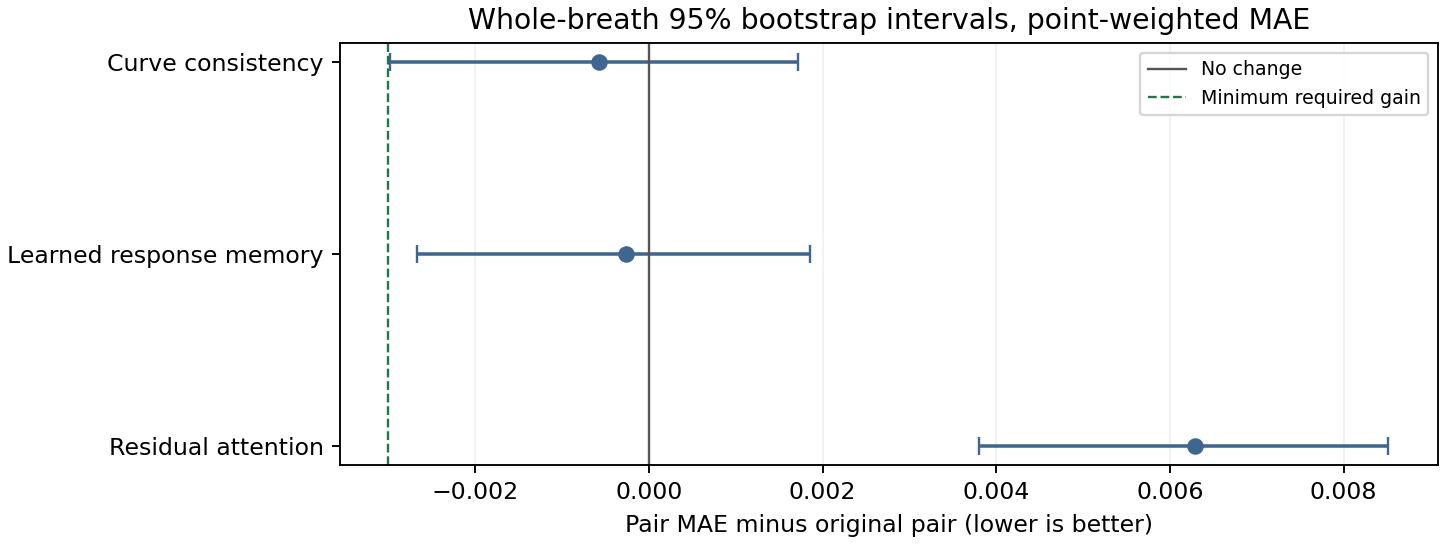

In [2]:
fig,ax=plt.subplots(figsize=(8.5,3.2),layout='constrained')
for i,(name,label) in enumerate(zip(names,labels)):
 ci=results[name]['interval'];m=ci['difference'];lo=ci['bootstrap_95_low'];hi=ci['bootstrap_95_high']
 ax.errorbar(m,i,xerr=[[m-lo],[hi-m]],fmt='o',capsize=4,color='#3e668f',markersize=6)
ax.axvline(0,color='#555555',linewidth=1,label='No change')
ax.axvline(-.003,color='#22774a',linestyle='--',linewidth=1,label='Minimum required gain')
ax.set_yticks(range(3),labels);ax.invert_yaxis();ax.set_xlabel('Pair MAE minus original pair (lower is better)')
ax.set_title('Whole-breath 95% bootstrap intervals, point-weighted MAE')
ax.grid(axis='x',alpha=.18);ax.legend(loc='upper right',fontsize=8)
fig.savefig(REVIEW/'paired_validation_differences.png',dpi=170);fig.savefig(REVIEW/'paired_validation_differences.svg');display(Image(filename=str(REVIEW/'paired_validation_differences.png')));plt.close(fig)

The small curve and memory gains are uncertain: both intervals include zero and neither reaches the predeclared .003 improvement. Attention is worse under this recipe. The median absolute point error is a secondary measure; it does not replace official mean MAE.

403 checks verify hashes, exact validation IDs/masks, native-unit scores and bootstrap calculations, original recipes/seeds/rates,200 completed epochs, best/last checkpoint states, training-only preprocessing and stored actual-GPU proofs. Feature matrices were not independently rebuilt; their data/source fingerprints match the original compact run.

No D confirmation, all-data refit or new submission was justified. All models, predictions and logs remain preserved in the verified43-file archive and local outputs. The .10 official target remains unmet. Further controlled iterations use the standing user approval and require fresh grouped confirmation before promotion.